# Лабораторна робота № 4. Реплікація MongoDB: відмовостійкість і лічильник

Дисципліна «Проєктування високонавантажених систем», викладач Родіонов А. М.

Виконав: Вовкотруб Олександр Віталійович, група ФБ-61мн.
КПІ ім. Ігоря Сікорського, ННФТІ, кафедра інформаційної безпеки.

Ноутбук є аналітичною частиною звіту. Усі числа, таблиці й рисунки звіту
обчислюються тут із виміряних даних `reports/data/task4-*.csv`, протоколи
терміналу частини I беруться з `reports/logs/task4-part1-*.txt`, а розбір
відмов primary з `reports/logs/task4-failover-*.txt`. Наприкінці є жива
перевірка: справжній replica set і `mongo-bench` на зменшеному навантаженні.

## 0. Підготовка середовища

Корінь репозиторію шукаємо від поточної теки вгору до `Package.swift`, тому
ноутбук працює і зі своєї теки, і з кореня. Прапорець `RUN_LIVE` вмикає
розділ 7 зі справжнім replica set; вимкнути його можна змінною оточення
`HLS_NB_LIVE=0`.

In [1]:
import json
import os
import re
import shutil
import socket
import subprocess
import tempfile
import time
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "Package.swift").is_file():
            return path
    raise FileNotFoundError("Package.swift не знайдено вище від " + str(start))


ROOT = find_root(Path.cwd().resolve())
# Тека ноутбука: поточна, якщо ноутбук запущено з неї, інакше його
# місце в репозиторії.
LAB = Path.cwd() if (Path.cwd() / "solution.ipynb").is_file() else next(
    p for p in (ROOT / "lab4", ROOT / "Labs" / "04-mongodb") if p.is_dir())
DATA = ROOT / "reports" / "data"
LOGS = ROOT / "reports" / "logs"
ASSETS = LAB / "assets"
ASSETS.mkdir(exist_ok=True)

RUN_LIVE = os.environ.get("HLS_NB_LIVE", "1") != "0"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 100,
})
pd.set_option("display.width", 160)

# Ті самі кольори, що й у ноутбуках робіт № 1...3: один колір на прогін або
# сховище в усіх рисунках.
INK, GRID = "#1A233B", "#D7DAE3"
RUN_COLOR = {
    "w1": "#0E6BA8",
    "majority": "#1B8A5E",
    "w1-kill": "#0E6BA8",
    "majority-kill": "#1B8A5E",
    "majority-kill-noretry": "#B5432F",
}
RUNS = list(RUN_COLOR)
STORE_COLOR = {
    "In-memory": "#6B7280",
    "Hazelcast (CP)": "#1B8A5E",
    "MongoDB (majority)": "#7A4FB5",
    "PostgreSQL": "#0E6BA8",
    "Disk (fsync)": "#B5432F",
}
EXPECTED = 100_000


def uk(x: float, digits: int = 0) -> str:
    """Число в українському записі: 4 447,0 (нерозривний пробіл, кома)."""
    return f"{x:,.{digits}f}".replace(",", "\u00a0").replace(".", ",")


def save(fig, name: str) -> Path:
    """Зберегти рисунок у assets/ (dpi 200) і показати його в ноутбуці."""
    path = ASSETS / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path), width=820))
    print("збережено:", path.relative_to(ROOT))
    return path


def excerpt(rel: str, start: str, end: str | None = None, *, lines: int | None = None) -> None:
    """Надрукувати точний уривок файла з номерами рядків.

    Уривок починається з першого рядка, що містить `start`, і закінчується
    першим наступним рядком, що містить `end` (або через `lines` рядків).
    """
    text = (ROOT / rel).read_text(encoding="utf-8").splitlines()
    first = next(i for i, line in enumerate(text) if start in line)
    if end is not None:
        last = next(i for i in range(first + 1, len(text)) if end in text[i])
    else:
        last = first + (lines or 1) - 1
    print(f"{rel}, рядки {first + 1}...{last + 1}")
    for i in range(first, last + 1):
        print(f"{i + 1:4d} | {text[i]}")


print("корінь репозиторію:", ROOT.name)
print("RUN_LIVE =", RUN_LIVE)

корінь репозиторію: HighLoadSystems
RUN_LIVE = True


## 1. Постановка

Replica set `rs0` з трьох процесів `mongod` 8.2.12 на одній машині (P-S-S),
вузли `127.0.0.1:21430...21432`.

Частина I. Три сценарії в `mongosh`: запис з `w: 3` при вимкненому вузлі без
тайм-ауту і з `wtimeout`, перевибори primary після його зупинки.

Частина II. Один документ з лічильником `likes`; 10 окремих клієнтів
одночасно роблять по 10 000 `findOneAndUpdate({ $inc: { likes: 1 } })`,
тобто очікується 100 000. Прогони:

| Прогін | Write concern | Що відбувається |
|---|---|---|
| `w1` | `{ w: 1 }` | без відмов |
| `majority` | `{ w: "majority" }` | без відмов |
| `w1-kill` | `{ w: 1 }` | primary отримує SIGKILL на 35 % часу прогону |
| `majority-kill` | `{ w: "majority" }` | те саме |
| `majority-kill-noretry` | `{ w: "majority" }` | те саме, але повтори без `lsid` і `txnNumber` (контрольний прогін) |

Частина III. MongoDB з `w: "majority"` як сховище веб-лічильника з роботи
№ 1, 10 клієнтів по 10 000 запитів, порівняння з пам'яттю, диском,
PostgreSQL і Hazelcast.

Кожен прогін, крім контрольного, виконано тричі; у таблицях медіана,
мінімум і максимум.

## 2. Частина I: протоколи терміналу

`scripts/task4-part1.sh` виконує кожен сценарій і записує протокол: команди
оболонки з часом UTC і сесії `mongosh` з підказкою перед кожною введеною
командою. Зі цих самих файлів зроблено знімки терміналу у звіті
(рисунки 3.1...3.8). Нижче протоколи повністю, а потім час і стани вузлів,
які з них витягує код.

In [2]:
transcripts = {n: (LOGS / f"task4-part1-{n}.txt").read_text(encoding="utf-8") for n in (1, 2, 3)}
for n, text in transcripts.items():
    print(f"=============== reports/logs/task4-part1-{n}.txt ===============")
    print(text)

=============== reports/logs/task4-part1-1.txt ===============
# Сценарій 1. Один secondary вимкнено, запис з writeConcern { w: 3, wtimeout: 0 } (без тайм-ауту).
# Час у [квадратних дужках] і в ISODate(...) указано в UTC.
# mongosh читає команди зі stdin: текст після підказки rs0 [...]> і є введеною командою.

[17:45:51.038] $ scripts/mongo.sh status
rs0, term 1, seen from node1
node1  127.0.0.1:21430  PRIMARY                   health 1  optime 1793641547:16  (pid 553720)
node2  127.0.0.1:21431  SECONDARY                 health 1  optime 1793641547:16  lag 0 s  sync node1  (pid 553814)
node3  127.0.0.1:21432  SECONDARY                 health 1  optime 1793641547:16  lag 0 s  sync node1  (pid 553903)

[17:45:53.010] $ scripts/mongo.sh stop-node 3
node 3 stopped (SIGTERM, pid 553903), exited after 15.0 s
[17:46:08.196] $ scripts/mongo.sh wait-down 3
node1 sees node3 as (not reachable/healthy) after 0.5 s (Error connecting to 127.0.0.1:21432 :: caused by :: onInvoke :: caused by :: Connec

In [3]:
t1, t2, t3 = transcripts[1], transcripts[2], transcripts[3]


def after(text: str, command: str) -> str:
    """Рядок, який mongosh надрукував одразу після введеної команди."""
    lines = text.splitlines()
    i = next(i for i, line in enumerate(lines) if line.endswith("> " + command))
    return lines[i + 1].strip()


part1 = {}
# Сценарій 1: w: 3 без тайм-ауту чекає, доки повернеться вузол 3.
part1["1: час вставки з w: 3, с"] = float(after(t1, "(t1 - t0) / 1000"))
part1["1: вставка підтверджена"] = "acknowledged: true" in t1
start_node3 = re.search(r"\[(\d\d:\d\d:\d\d\.\d+)\] \$ scripts/mongo.sh start-node 3", t1)[1]
returned = re.search(r"let t1 = new Date\(\); t1\nISODate\('([^']+)'\)", t1)[1]
part1["1: від start-node 3 до відповіді, с"] = round(
    (pd.Timestamp(returned) - pd.Timestamp(f"{returned[:10]}T{start_node3}Z")).total_seconds(), 3)
part1["1: під час очікування документ читається з majority"] = \
    t1.count("note: 'w: 3, wtimeout: 0'") >= 3
# Сценарій 2: wtimeout 5000 мс.
part1["2: час до WriteConcernError, с"] = float(after(t2, "(new Date() - t0) / 1000"))
part1["2: код помилки"] = int(re.search(r"code: (\d+),\s*codeName: 'WriteConcernTimeout'", t2)[1])
part1["2: n у відповіді"] = int(re.search(r"Result: \{\s*n: (\d+)", t2)[1])
part1["2: документ знайдено разів (primary, node2, node3)"] = t2.count("note: 'w: 3, wtimeout: 5000'")
# Сценарій 3: перевибори.
part1["3: причина виборів"] = re.search(r"lastElectionReason: '(\w+)'", t3)[1]
part1["3: новий term"] = int(re.search(r"electionTerm: Long\('(\d+)'\)", t3)[1])
part1["3: новий primary"] = after(t3, "db.hello().primary")
part1["3: від stop-node 1 до виборів, с"] = float(after(
    t3, '(rs.status().electionCandidateMetrics.lastElectionDate - ISODate("2026-11-02T17:47:07.191Z")) / 1000'))
part1["3: majority-записи доступні після виборів, с"] = round(
    (pd.Timestamp(re.search(r"wMajorityWriteAvailabilityDate: ISODate\('([^']+)'\)", t3)[1])
     - pd.Timestamp(re.search(r"lastElectionDate: ISODate\('([^']+)'\)", t3)[1])).total_seconds(), 3)
part1["3: node1 після повернення бачить документів"] = t3.split("shell 1")[1].count("scenario: 3, n:")
caught = re.findall(r"(node\d) is SECONDARY and caught up with \w+ after ([\d.]+) s", "\n".join(transcripts.values()))
part1["наздоганяння після start-node, с"] = ", ".join(f"{node} {s}" for node, s in caught)
display(pd.Series(part1, name="значення").to_frame())

assert part1["1: вставка підтверджена"] and part1["1: час вставки з w: 3, с"] == 10.623
assert part1["2: код помилки"] == 64 and part1["2: n у відповіді"] == 1
assert part1["2: час до WriteConcernError, с"] == 5.049
assert part1["2: документ знайдено разів (primary, node2, node3)"] == 5  # 2 на primary, 2 на node2, 1 на node3
assert part1["3: новий primary"] == "127.0.0.1:21431" and part1["3: новий term"] == 2
assert part1["3: від stop-node 1 до виборів, с"] == 0.029
assert part1["3: node1 після повернення бачить документів"] == 3

,значення
"1: час вставки з w: 3, с",10.623
1: вставка підтверджена,True
"1: від start-node 3 до відповіді, с",1.571
1: під час очікування документ читається з majority,True
"2: час до WriteConcernError, с",5.049
2: код помилки,64
2: n у відповіді,1
"2: документ знайдено разів (primary, node2, node3)",5
3: причина виборів,stepUpRequestSkipDryRun
3: новий term,2


Сценарій 1: вставка з `w: 3` повернулася через 10,623 с, приблизно через
1,6 с після того, як вузол 3 запустили знову; поки вона чекала, документ
уже читався на primary і з `readConcern("majority")`. Сценарій 2:
`WriteConcernTimeout` (код 64) через 5,049 с, але `n: 1`, і документ є на
primary, на node2 (зокрема з `majority`) і, після повернення, на node3:
тайм-аут write concern запис не скасовує. Сценарій 3: після SIGTERM
primary передав роль node2 (`stepUpRequestSkipDryRun`, term 2) за 0,029 с;
старий primary повернувся як SECONDARY і має всі три документи, записані
без нього.

## 3. Клієнт: інкремент як retryable write

MongoKitten не реалізує retryable writes, тому клієнт сам будує команду
`findAndModify` з `lsid` сесії і новим `txnNumber` на кожен логічний запис.
Повтор надсилає ту саму команду з тим самим `txnNumber`, і сервер, який уже
виконав її, повертає збережений результат замість другого `$inc`:

In [4]:
excerpt("Sources/CounterCore/MongoCounterClient.swift", "private func retryableWrite(", "return try await retrying {")

Sources/CounterCore/MongoCounterClient.swift, рядки 173...192
 173 |     private func retryableWrite(
 174 |         documentID: String? = nil,
 175 |         update: Document,
 176 |         writeConcern: MongoWriteConcern? = nil
 177 |     ) async throws -> MongoOutcome<Int> {
 178 |         var command: Document = [
 179 |             "findAndModify": location.collection,
 180 |             "query": ["_id": documentID ?? location.documentID] as Document,
 181 |             "update": update,
 182 |             "new": true,
 183 |             "upsert": true,
 184 |             "writeConcern": (writeConcern ?? self.writeConcern).document,
 185 |         ]
 186 |         if retryableWrites {
 187 |             // A new logical write: the next transaction number. Every retry
 188 |             // of it sends this same number.
 189 |             command["lsid"] = ["id": sessionID] as Document
 190 |             command["txnNumber"] = lastTransactionNumber.add(1, ordering: .relaxed).newVal

Веб-сховище тримає пул з 10 таких клієнтів і позичає по одному на запит,
бо `txnNumber` однієї сесії мусить зростати, а не перемежовуватися:

In [5]:
excerpt("Sources/CounterCore/MongoCounterStore.swift", "public func increment() async", lines=3)

Sources/CounterCore/MongoCounterStore.swift, рядки 51...53
  51 |     public func increment() async throws {
  52 |         try await clients.withLease { _ = try await $0.increment() }
  53 |     }


## 4. Частина II: 10 клієнтів по 10 000 інкрементів

Сирі дані `reports/data/task4-bench.csv`, рядок на прогін. `acknowledged`:
інкременти, які сервер підтвердив; `lost_acknowledged`: різниця між ними
і фінальним значенням; `retries`: повторні надсилання після помилок;
`server_deduplicated`: приріст `serverStatus().transactions.retriedStatementsCount`,
тобто повтори, які сервер упізнав як уже виконані.

In [6]:
bench = pd.read_csv(DATA / "task4-bench.csv")
assert set(bench["run"]) == set(RUNS)
assert (bench["workers"] * bench["increments_per_worker"] == EXPECTED).all()
assert (bench["expected"] == EXPECTED).all() and (bench["acknowledged"] == EXPECTED).all()
assert (bench["errors"] == 0).all() and (bench["rollback_lines"] == 0).all()
bench[["repeat", "run", "seconds", "ops_per_sec", "final_value", "lost_acknowledged", "retries",
       "server_deduplicated", "killed_node", "kill_at_seconds", "failover_seconds", "elections"]]

,repeat,run,seconds,ops_per_sec,final_value,lost_acknowledged,retries,server_deduplicated,killed_node,kill_at_seconds,failover_seconds,elections
0,1,w1,21.9997,4545.5,100000,0,0,0,NaN,NaN,NaN,0
1,1,majority,101.5172,985.1,100000,0,0,0,NaN,NaN,NaN,0
2,2,w1,22.4869,4447.0,100000,0,0,0,NaN,NaN,NaN,0
3,2,majority,100.0766,999.2,100000,0,0,0,NaN,NaN,NaN,0
4,3,w1,29.1806,3426.9,100000,0,0,0,NaN,NaN,NaN,0
5,3,majority,103.4099,967.0,100000,0,0,0,NaN,NaN,NaN,0
6,1,w1-kill,34.4842,2899.9,99996,4,480,0,2.0,8.084,11.071,1
7,1,majority-kill,109.3340,914.6,100000,0,470,10,1.0,35.672,10.821,1
8,2,w1-kill,34.6597,2885.2,99999,1,490,2,2.0,8.088,11.315,1
9,2,majority-kill,112.3606,890.0,100000,0,480,7,1.0,35.672,11.095,1


Таблиця 4.1 звіту: час і пропускна здатність (медіана, мінімум, максимум).

In [7]:
g = bench.groupby("run", sort=False)
part2 = pd.DataFrame({
    "прогонів": g.size(),
    "медіана, с": g["seconds"].median(),
    "мін., с": g["seconds"].min(),
    "макс., с": g["seconds"].max(),
    "інкр./с (медіана)": g["ops_per_sec"].median(),
}).loc[RUNS]
display(part2.round(2))

PUBLISHED_41 = {  # прогін: (медіана, мін., макс., інкр./с), як у таблиці 4.1 звіту
    "w1": (22.49, 22.00, 29.18, 4447.0),
    "majority": (101.52, 100.08, 103.41, 985.1),
    "w1-kill": (34.66, 34.48, 35.73, 2885.2),
    "majority-kill": (112.36, 109.33, 139.85, 890.0),
    "majority-kill-noretry": (168.40, 168.40, 168.40, 593.8),
}
for run, values in PUBLISHED_41.items():
    row = part2.loc[run]
    got = (round(row["медіана, с"], 2), round(row["мін., с"], 2), round(row["макс., с"], 2),
           round(row["інкр./с (медіана)"], 1))
    assert got == values, (run, got, values)

,прогонів,"медіана, с","мін., с","макс., с",інкр./с (медіана)
run,,,,,
w1,3,22.49,22.00,29.18,4447.0
majority,3,101.52,100.08,103.41,985.1
w1-kill,3,34.66,34.48,35.73,2885.2
majority-kill,3,112.36,109.33,139.85,890.0
majority-kill-noretry,1,168.40,168.40,168.40,593.8


Таблиця 4.2 звіту: фінальне значення, втрачені підтверджені інкременти,
повтори і повтори, упізнані сервером, у кожному прогоні.

In [8]:
per_run = (bench.sort_values("repeat").groupby("run", sort=False)
           .agg(фінальне=("final_value", list), втрачено=("lost_acknowledged", list),
                повтори=("retries", list), упізнано_сервером=("server_deduplicated", list))
           .loc[RUNS])
display(per_run)

PUBLISHED_42 = {  # прогін: (фінальні значення, втрачено, повтори, упізнано сервером)
    "w1": ([100000] * 3, [0, 0, 0], [0, 0, 0], [0, 0, 0]),
    "majority": ([100000] * 3, [0, 0, 0], [0, 0, 0], [0, 0, 0]),
    "w1-kill": ([99996, 99999, 100000], [4, 1, 0], [480, 490, 450], [0, 2, 0]),
    "majority-kill": ([100000] * 3, [0, 0, 0], [470, 480, 426], [10, 7, 9]),
    "majority-kill-noretry": ([100010], [-10], [450], [0]),
}
for run, values in PUBLISHED_42.items():
    assert tuple(per_run.loc[run]) == values, (run, tuple(per_run.loc[run]), values)

,фінальне,втрачено,повтори,упізнано_сервером
run,,,,
w1,"[100000, 100000, 100000]","[0, 0, 0]","[0, 0, 0]","[0, 0, 0]"
majority,"[100000, 100000, 100000]","[0, 0, 0]","[0, 0, 0]","[0, 0, 0]"
w1-kill,"[99996, 99999, 100000]","[4, 1, 0]","[480, 490, 450]","[0, 2, 0]"
majority-kill,"[100000, 100000, 100000]","[0, 0, 0]","[470, 480, 426]","[10, 7, 9]"
majority-kill-noretry,[100010],[-10],[450],[0]


In [9]:
t = part2["медіана, с"]
r = part2["інкр./с (медіана)"]
print(f"majority / w1 за часом: {t['majority'] / t['w1']:.2f}")
print(f"додано відмовою: w1 {t['w1-kill'] - t['w1']:.2f} с, majority {t['majority-kill'] - t['majority']:.2f} с")
print(f"середня затримка інкремента (10 клієнтів / інкр./с): "
      f"w1 {1000 * 10 / r['w1']:.2f} мс, majority {1000 * 10 / r['majority']:.2f} мс")
kills = bench[bench["kill"]]
print(f"від kill до першого підтвердження: {kills['failover_seconds'].min():.2f}...{kills['failover_seconds'].max():.2f} с")
print(f"найдовший окремий інкремент у прогонах з kill: {kills['longest_op_seconds'].min():.2f}...{kills['longest_op_seconds'].max():.2f} с")
print(f"w1-kill: втрачено разом {int(bench.loc[bench['run'] == 'w1-kill', 'lost_acknowledged'].sum())} "
      f"підтверджених інкрементів з 300 000")
print("повторів на клієнта за секунду без primary:",
      ", ".join(f"{x:.1f}" for x in kills["retries"] / 10 / kills["failover_seconds"]))

exact = bench[bench["run"] != "w1-kill"].query("retryable_writes")
assert (exact["final_value"] == EXPECTED).all(), "усі прогони, крім w1-kill і контрольного, мають дати рівно 100 000"
assert (bench["elections"] == bench["kill"].astype(int)).all(), "одні вибори на кожен прогін з kill"

majority / w1 за часом: 4.51
додано відмовою: w1 12.17 с, majority 10.84 с
середня затримка інкремента (10 клієнтів / інкр./с): w1 2.25 мс, majority 10.15 мс
від kill до першого підтвердження: 10.30...11.31 с
найдовший окремий інкремент у прогонах з kill: 10.44...11.48 с
w1-kill: втрачено разом 5 підтверджених інкрементів з 300 000
повторів на клієнта за секунду без primary: 4.3, 4.3, 4.3, 4.3, 4.4, 3.9, 4.4


Рисунок 4.1 звіту: смуга це медіана, риска з засічками мінімум і максимум,
точки окремі повтори. У прогонах з kill частину часу займає пауза без
primary (від kill до першого підтвердження, медіана підписана).

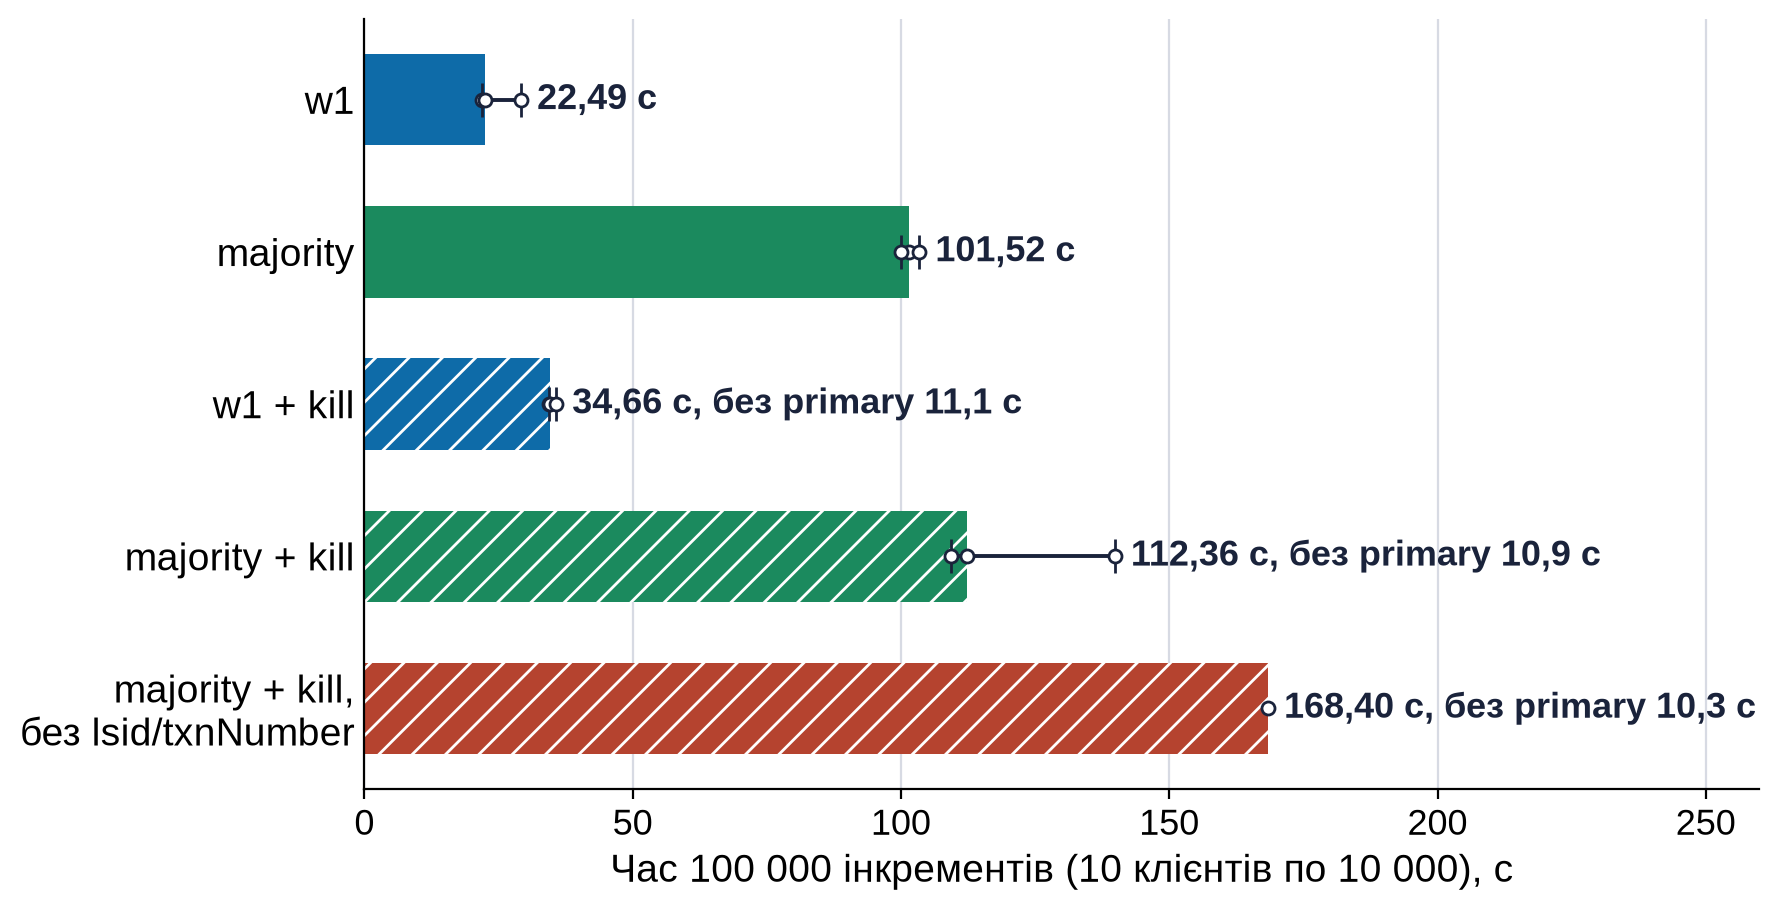

збережено: Labs/04-mongodb/assets/01-part2-time.png


In [10]:
LABEL = {
    "w1": "w1",
    "majority": "majority",
    "w1-kill": "w1 + kill",
    "majority-kill": "majority + kill",
    "majority-kill-noretry": "majority + kill,\nбез lsid/txnNumber",
}
fig, ax = plt.subplots(figsize=(9, 5.0))
order = RUNS[::-1]  # перший прогін зверху
for i, run in enumerate(order):
    row = part2.loc[run]
    runs = bench.loc[bench["run"] == run]
    kill = bool(runs["kill"].iloc[0])
    ax.barh(i, row["медіана, с"], height=0.6, color=RUN_COLOR[run], zorder=2,
            hatch="//" if kill else None, edgecolor="white" if kill else None, linewidth=0)
    if row["прогонів"] > 1:
        ax.errorbar(row["медіана, с"], i,
                    xerr=[[row["медіана, с"] - row["мін., с"]], [row["макс., с"] - row["медіана, с"]]],
                    fmt="none", ecolor=INK, elinewidth=1.4, capsize=6, zorder=3)
    ax.scatter(runs["seconds"], [i] * len(runs), s=22, color="white", edgecolor=INK, linewidth=1, zorder=4)
    label = f"{uk(row['медіана, с'], 2)} с"
    if kill:
        label += f", без primary {uk(runs['failover_seconds'].median(), 1)} с"
    ax.text(row["макс., с"] + 3, i, label, va="center", ha="left", color=INK, fontsize=13, fontweight="bold")
ax.set_yticks(range(len(order)), [LABEL[r] for r in order])
ax.set_xlim(0, 260)
ax.set_xlabel("Час 100 000 інкрементів (10 клієнтів по 10 000), с")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
save(fig, "01-part2-time.png");

Рисунок 4.2 звіту: відхилення фінального значення від 100 000 у кожному
повторі. Нуль означає точний лічильник; мінус це втрачені підтверджені
інкременти, плюс це інкременти, пораховані двічі.

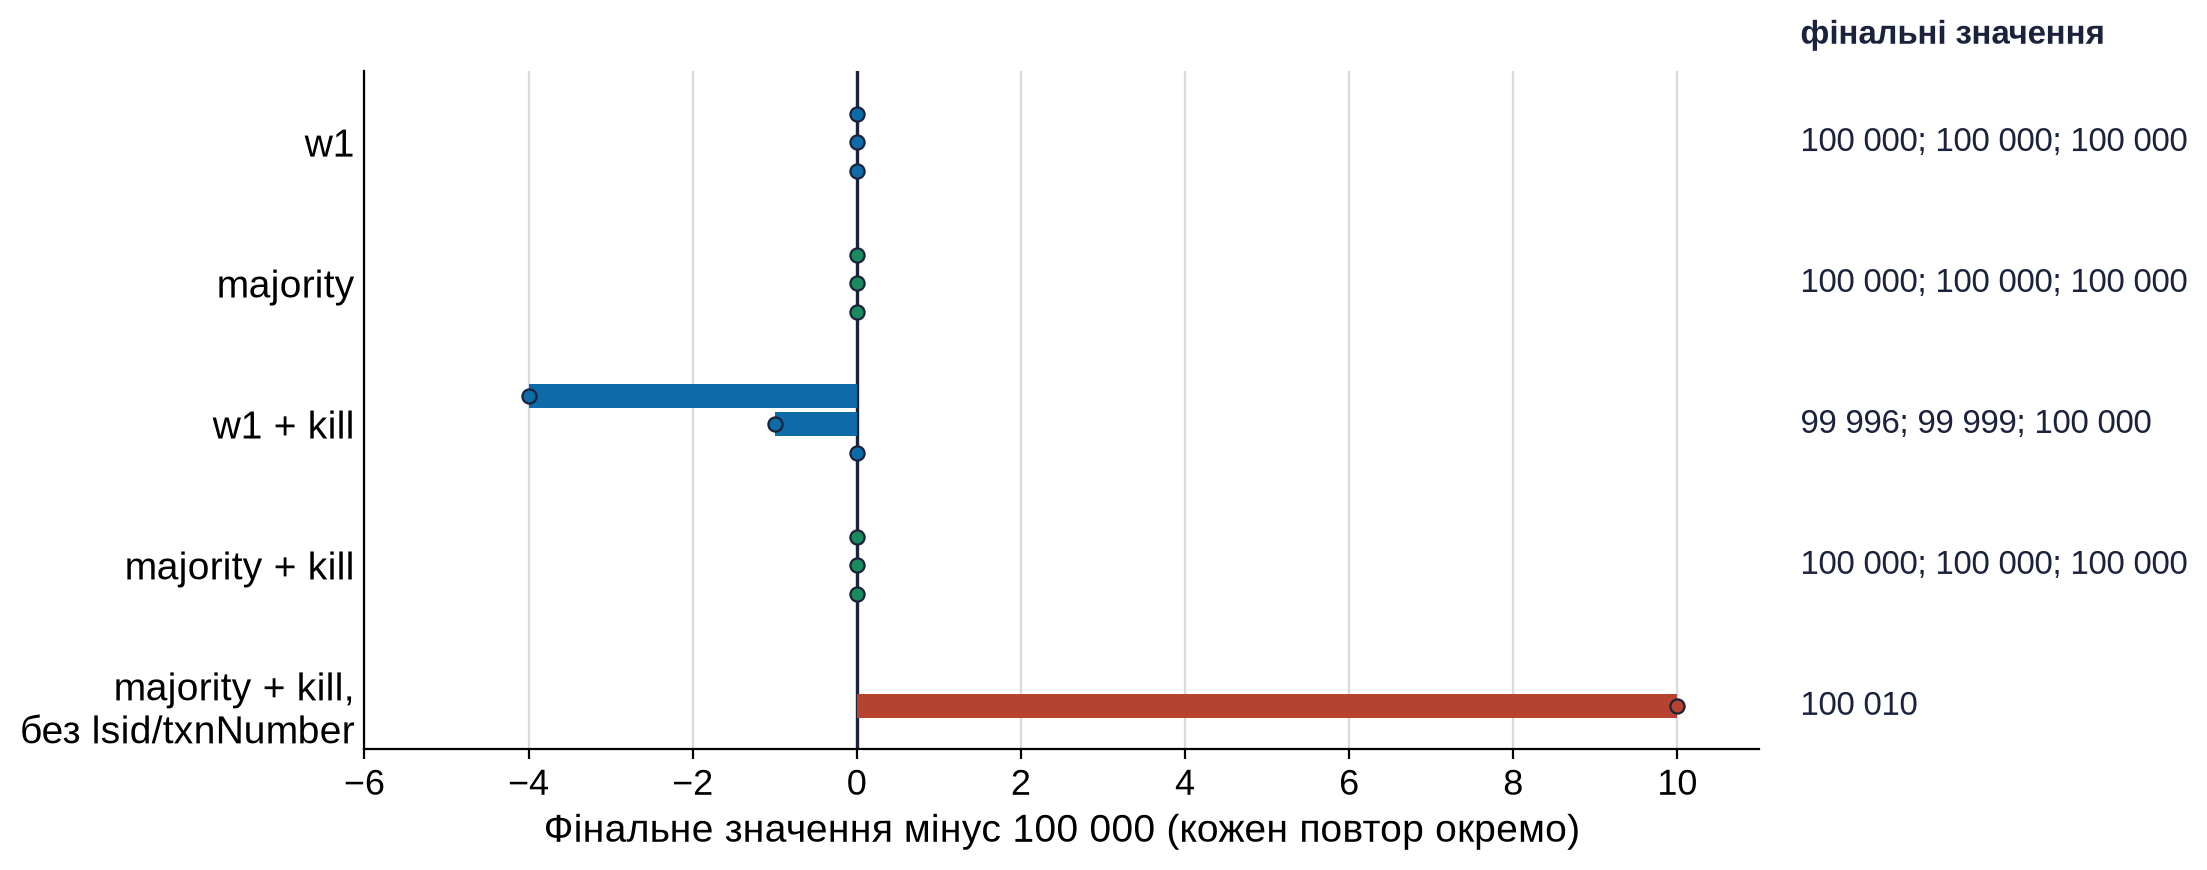

збережено: Labs/04-mongodb/assets/02-part2-final-value.png


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, run in enumerate(order):
    runs = bench.loc[bench["run"] == run].sort_values("repeat")
    dev = runs["final_value"] - EXPECTED
    offsets = [0.0] if len(runs) == 1 else [0.2, 0.0, -0.2][:len(runs)]  # повтор 1 зверху
    ax.barh([i + o for o in offsets], dev, height=0.17, color=RUN_COLOR[run], zorder=2)
    ax.scatter(dev, [i + o for o in offsets], s=26, color=RUN_COLOR[run], edgecolor=INK, linewidth=0.8, zorder=3)
    text = "; ".join(uk(v) for v in runs["final_value"])
    ax.text(11.5, i, text, va="center", ha="left", color=INK, fontsize=12)
ax.axvline(0, color=INK, linewidth=1.2, zorder=1)
ax.set_yticks(range(len(order)), [LABEL[r] for r in order])
ax.set_xlim(-6, 11)
ax.set_xticks(range(-6, 11, 2))
ax.set_xlabel("Фінальне значення мінус 100 000 (кожен повтор окремо)")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.text(11.5, len(order) - 0.35, "фінальні значення", ha="left", va="bottom", color=INK, fontsize=12,
        fontweight="bold")
save(fig, "02-part2-final-value.png");

Без відмов обидва write concern дають рівно 100 000, а `majority` у 4,5
раза повільніший: середня затримка інкремента 10,2 мс проти 2,2 мс, бо
`majority` чекає запису в журнал на більшості вузлів. Після SIGKILL
primary кожен прогін простоює 10,3...11,3 с, доки решта вузлів не обере
новий primary (`electionTimeoutMillis` 10 000 мс). `w1-kill` втратив 4, 1
і 0 підтверджених інкрементів. `majority-kill` у всіх трьох повторах дав
рівно 100 000, а контрольний прогін без `lsid` і `txnNumber` дав 100 010:
10 інкрементів, що були в дорозі під час відмови, пораховано двічі.

## 5. Відмова primary за логами mongod

Для кожного прогону з kill `scripts/task4.sh` зберіг вивід `mongo-bench` і
рядки журналів усіх трьох вузлів за час прогону
(`reports/logs/task4-failover-<прогін>-<повтор>.txt`). Звідти беремо, хто
став primary і в якому term, і дві позиції oplog: `targetOpTime`, до якої
новий primary наздогнав дані після виборів, і `oplogTruncateAfterPoint`,
до якої вбитий вузол обрізав свій oplog під час відновлення після
аварійного вимкнення, тобто що з його записів реально встигло на диск.

In [12]:
def optime(value: str) -> tuple[int, int]:
    seconds, increment = value.split(":")
    return int(seconds), int(increment)


failovers = []
for path in sorted(LOGS.glob("task4-failover-*.txt")):
    text = path.read_text(encoding="utf-8")
    m = re.match(r"task4-failover-(.+)-(\d+)\.txt", path.name)
    elected = re.search(r"^\S+\s+(node\d)\s+ELECTION Election succeeded, assuming primary role\s+\{\"term\":(\d+)\}",
                        text, re.M)
    target = optime(re.search(r'"targetOpTime":\{"ts":"([\d:]+)"', text)[1])
    truncated = optime(re.search(r'"oplogTruncateAfterPoint":\{"":"([\d:]+)"\}', text)[1])
    assert target[0] == truncated[0], "обидві позиції в одній секунді, тож різниця це кількість записів oplog"
    failovers.append({
        "прогін": m[1], "повтор": int(m[2]),
        "новий primary": elected[1], "term": int(elected[2]),
        "записів oplog, яких не було на диску вбитого вузла": target[1] - truncated[1],
        "rollback": "ROLLBACK" in text and "Файлів rollback немає" not in text,
    })
failovers = pd.DataFrame(failovers)
failovers = failovers.merge(
    bench[["run", "repeat", "killed_node", "kill_at_seconds", "failover_seconds", "lost_acknowledged",
           "server_deduplicated"]],
    left_on=["прогін", "повтор"], right_on=["run", "repeat"]).drop(columns=["run", "repeat"])
failovers["прогін"] = pd.Categorical(failovers["прогін"], RUNS, ordered=True)
failovers = failovers.sort_values(["прогін", "повтор"]).reset_index(drop=True)
display(failovers)

gap = failovers.groupby("прогін", observed=True)["записів oplog, яких не було на диску вбитого вузла"].agg(list)
print(gap)
assert gap["w1-kill"] == [452, 2386, 346] and gap["majority-kill"] == [2, 8, 0]
assert not failovers["rollback"].any()

PUBLISHED_43 = [  # (прогін, повтор, kill с, вбито, новий primary, term, розрив, втрачено), таблиця 4.3 звіту
    ("w1-kill", 1, 8.08, "node2", "node1", 16, 452, 4),
    ("w1-kill", 2, 8.09, "node2", "node1", 18, 2386, 1),
    ("w1-kill", 3, 8.09, "node2", "node3", 20, 346, 0),
    ("majority-kill", 1, 35.67, "node1", "node2", 17, 2, 0),
    ("majority-kill", 2, 35.67, "node1", "node2", 19, 8, 0),
    ("majority-kill", 3, 36.01, "node3", "node2", 21, 0, 0),
]
got = [(row["прогін"], row["повтор"], round(row["kill_at_seconds"], 2), f"node{int(row['killed_node'])}",
        row["новий primary"], row["term"], row["записів oplog, яких не було на диску вбитого вузла"],
        row["lost_acknowledged"]) for _, row in failovers.iterrows() if row["прогін"] != "majority-kill-noretry"]
assert got == PUBLISHED_43, got

,прогін,повтор,новий primary,term,"записів oplog, яких не було на диску вбитого вузла",rollback,killed_node,kill_at_seconds,failover_seconds,lost_acknowledged,server_deduplicated
0,w1-kill,1,node1,16,452,False,2.0,8.084,11.071,4,0
1,w1-kill,2,node1,18,2386,False,2.0,8.088,11.315,1,2
2,w1-kill,3,node3,20,346,False,2.0,8.086,10.302,0,0
3,majority-kill,1,node2,17,2,False,1.0,35.672,10.821,0,10
4,majority-kill,2,node2,19,8,False,1.0,35.672,11.095,0,7
5,majority-kill,3,node2,21,0,False,3.0,36.007,10.879,0,9
6,majority-kill-noretry,1,node1,22,0,False,2.0,35.665,10.301,-10,0


прогін
w1-kill                  [452, 2386, 346]
majority-kill                   [2, 8, 0]
majority-kill-noretry                 [0]
Name: записів oplog, яких не було на диску вбитого вузла, dtype: object


Таблиця 4.3 звіту. У прогонах `w1-kill` вбитий primary після перезапуску
мав на диску на 346...2386 записів oplog менше, ніж новий primary: з
`w: 1` журнал скидається на диск періодично (раз на 100 мс), а secondary
журналюють кожну застосовану пачку. Записи, які primary підтвердив, але не
встиг ні віддати secondary, ні записати в журнал, зникли разом з його
пам'яттю, тому rollback не було. У прогонах `majority-kill` розрив
0...8 записів, бо кожен запис з `majority` примусово синхронізує журнал.

In [13]:
print("уривок журналів, w1-kill, повтор 1:")
lines = (LOGS / "task4-failover-w1-kill-1.txt").read_text(encoding="utf-8").splitlines()
for line in lines:
    if re.search(r"ELECTION (Starting|Election succeeded)|Caught up to the latest|Removing unapplied|"
                 r"Recovering from stable|SERVER RESTARTED|Member is now in state DOWN", line):
        print(line[:150])

уривок журналів, w1-kill, повтор 1:
18:35:05.541  node3  REPL     Member is now in state DOWN  {"hostAndPort":"127.0.0.1:21431","heartbeatMessage":"Error connecting to 127.0.0.1:21431 ::
18:35:05.542  node1  REPL     Member is now in state DOWN  {"hostAndPort":"127.0.0.1:21431","heartbeatMessage":"Error connecting to 127.0.0.1:21431 ::
18:35:16.556  node1  ELECTION Starting an election, since we've seen no PRIMARY in election timeout period  {"electionTimeoutPeriodMillis":10000}
18:35:16.561  node1  ELECTION Election succeeded, assuming primary role  {"term":16}
18:35:16.562  node1  REPL     Caught up to the latest optime known via heartbeats after becoming primary  {"targetOpTime":{"ts":"1793644505:11766","t"
18:35:32.102  node2  CONTROL  ***** SERVER RESTARTED *****
18:35:32.863  node2  REPL     Removing unapplied oplog entries after oplogTruncateAfterPoint  {"oplogTruncateAfterPoint":{"":"1793644505:11314"}}
18:35:32.865  node2  REPL     Recovering from stable timestamp  {"stableTim

## 6. Частина III: веб-лічильник на MongoDB

`counter-server --store mongo`: `findAndModify` з `$inc` і
`w: "majority"`, читання `/count` з `readConcern: "majority"`. Дані для
порівняння: пам'ять і диск з `task1.csv` (лише рядки з 10 клієнтами),
PostgreSQL з `task2-web.csv`, Hazelcast з `task3-web.csv`, MongoDB з
`task4-web.csv`. Скрізь 10 клієнтів по 10 000 запитів.

In [14]:
t1csv = pd.read_csv(DATA / "task1.csv")
web = pd.concat([
    t1csv[t1csv["clients"] == 10],
    pd.read_csv(DATA / "task2-web.csv"),
    pd.read_csv(DATA / "task3-web.csv"),
    pd.read_csv(DATA / "task4-web.csv"),
], ignore_index=True)
web["сховище"] = web["store"].map({"memory": "In-memory", "disk": "Disk (fsync)", "postgres": "PostgreSQL",
                                   "hazelcast": "Hazelcast (CP)", "mongo": "MongoDB (majority)"})
assert (web["total_requests"] == EXPECTED).all() and web["correct"].all()
display(web[["сховище", "repeat", "seconds", "rps", "final_value", "correct"]])

STORES = ["In-memory", "Disk (fsync)", "PostgreSQL", "Hazelcast (CP)", "MongoDB (majority)"]
w = web.groupby("сховище")
part3 = pd.DataFrame({
    "медіана, с": w["seconds"].median(),
    "мін., с": w["seconds"].min(),
    "макс., с": w["seconds"].max(),
    "запитів/с (медіана)": w["rps"].median(),
    "мін. запитів/с": w["rps"].min(),
    "макс. запитів/с": w["rps"].max(),
}).loc[STORES]
display(part3.round(2))

PUBLISHED_44 = {  # сховище: (медіана, мін., макс., запитів/с), як у таблиці 4.4 звіту
    "In-memory": (3.20, 2.92, 3.31, 31256.0),
    "Disk (fsync)": (818.08, 814.26, 824.12, 122.2),
    "PostgreSQL": (302.44, 199.76, 306.17, 330.6),
    "Hazelcast (CP)": (8.88, 8.79, 9.08, 11259.7),
    "MongoDB (majority)": (133.59, 121.80, 156.01, 748.6),
}
for store, values in PUBLISHED_44.items():
    row = part3.loc[store]
    got = (round(row["медіана, с"], 2), round(row["мін., с"], 2), round(row["макс., с"], 2),
           round(row["запитів/с (медіана)"], 1))
    assert got == values, (store, got, values)

,сховище,repeat,seconds,rps,final_value,correct
0,In-memory,1,2.9155,34299.7,100000,True
1,In-memory,2,3.3096,30215.1,100000,True
2,In-memory,3,3.1994,31256.0,100000,True
3,Disk (fsync),1,818.0793,122.2,100000,True
4,Disk (fsync),2,814.2633,122.8,100000,True
5,Disk (fsync),3,824.1182,121.3,100000,True
6,PostgreSQL,1,199.7578,500.6,100000,True
7,PostgreSQL,2,302.4360,330.6,100000,True
8,PostgreSQL,3,306.1745,326.6,100000,True
9,Hazelcast (CP),1,8.7884,11378.6,100000,True


,"медіана, с","мін., с","макс., с",запитів/с (медіана),мін. запитів/с,макс. запитів/с
сховище,,,,,,
In-memory,3.20,2.92,3.31,31256.0,30215.1,34299.7
Disk (fsync),818.08,814.26,824.12,122.2,121.3,122.8
PostgreSQL,302.44,199.76,306.17,330.6,326.6,500.6
Hazelcast (CP),8.88,8.79,9.08,11259.7,11007.6,11378.6
MongoDB (majority),133.59,121.80,156.01,748.6,641.0,821.1


In [15]:
rps = part3["запитів/с (медіана)"]
mongo = rps["MongoDB (majority)"]
print(f"In-memory / MongoDB: {rps['In-memory'] / mongo:.1f}")
print(f"Hazelcast / MongoDB: {rps['Hazelcast (CP)'] / mongo:.1f}")
print(f"MongoDB / PostgreSQL: {mongo / rps['PostgreSQL']:.2f}")
print(f"MongoDB / Disk: {mongo / rps['Disk (fsync)']:.2f}")
print(f"веб-лічильник / mongo-bench majority: {mongo / r['majority']:.2f}")
spread = part3.loc["MongoDB (majority)"]
print(f"розкид часу MongoDB: {spread['мін., с']:.2f}...{spread['макс., с']:.2f} с, "
      f"{100 * (spread['макс., с'] - spread['мін., с']) / spread['медіана, с']:.1f} % від медіани")

In-memory / MongoDB: 41.8
Hazelcast / MongoDB: 15.0
MongoDB / PostgreSQL: 2.26
MongoDB / Disk: 6.13
веб-лічильник / mongo-bench majority: 0.76
розкид часу MongoDB: 121.80...156.01 с, 25.6 % від медіани


Рисунок 4.3 звіту: логарифмічна шкала, бо сховища відрізняються на два з
половиною порядки. Смуга це медіана, риска мінімум і максимум.

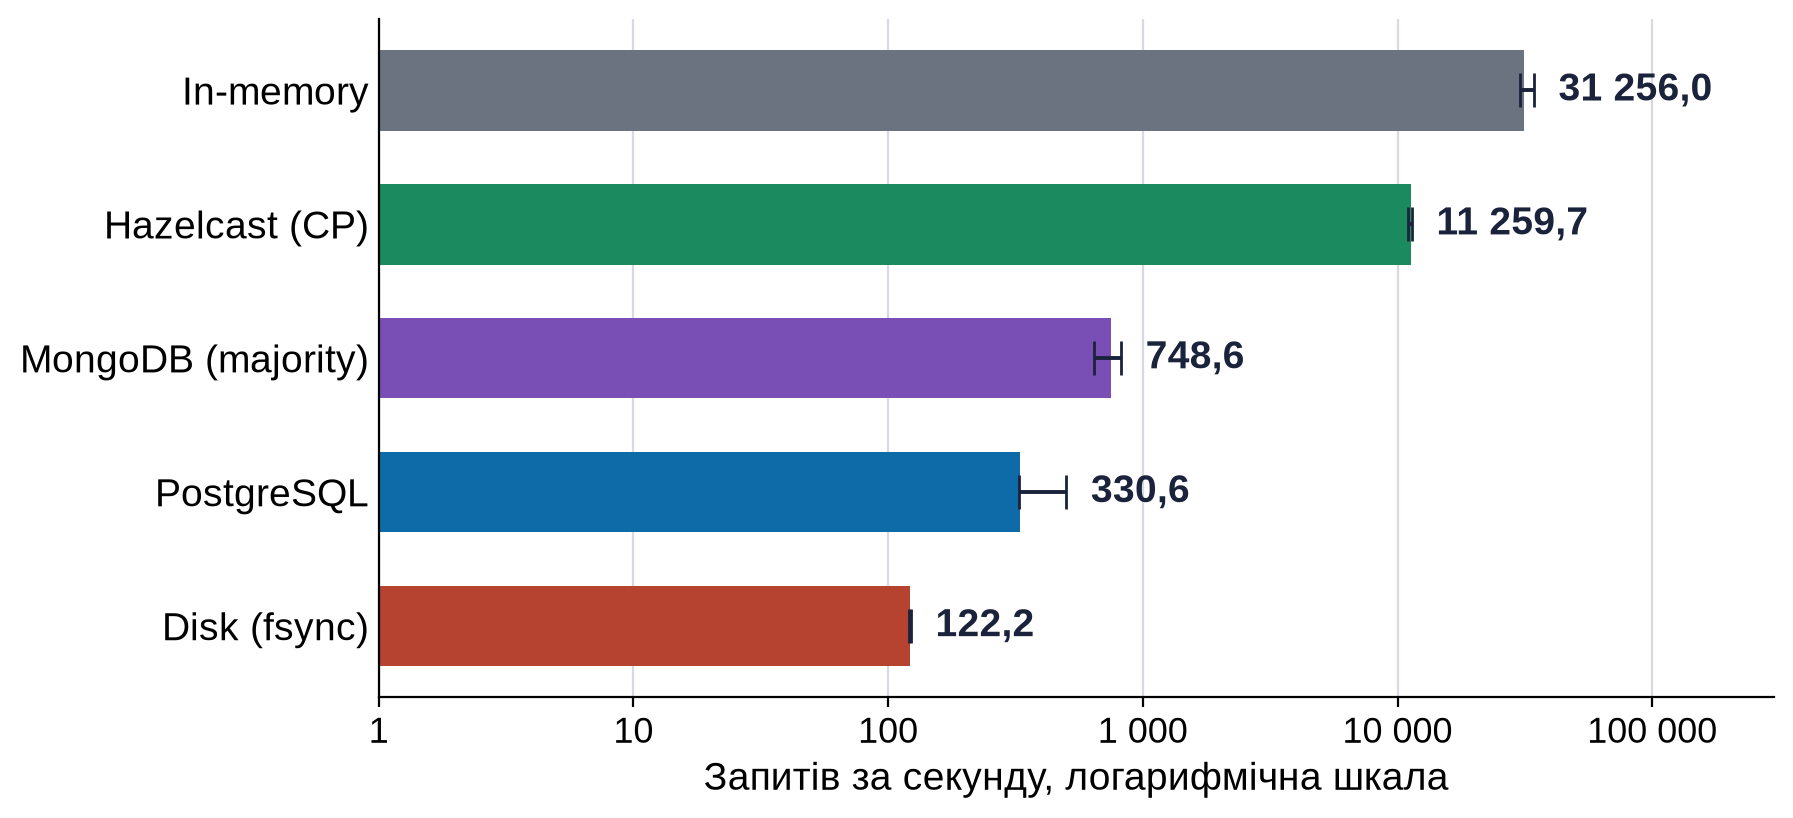

збережено: Labs/04-mongodb/assets/03-part3-stores-rps.png


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.4))
order3 = part3.sort_values("запитів/с (медіана)").index.tolist()  # найшвидше зверху
for i, s in enumerate(order3):
    row = part3.loc[s]
    med = row["запитів/с (медіана)"]
    ax.barh(i, med, height=0.6, color=STORE_COLOR[s], zorder=2)
    ax.errorbar(med, i, xerr=[[med - row["мін. запитів/с"]], [row["макс. запитів/с"] - med]],
                fmt="none", ecolor=INK, elinewidth=1.4, capsize=6, zorder=3)
    ax.text(row["макс. запитів/с"] * 1.25, i, uk(med, 1), va="center", ha="left",
            color=INK, fontsize=14, fontweight="bold")
ax.set_yticks(range(len(order3)), order3)
ax.set_xscale("log")
ax.set_xlim(1, 3e5)
ax.set_xticks([1, 10, 100, 1_000, 10_000, 100_000],
              ["1", "10", "100", uk(1_000), uk(10_000), uk(100_000)])
ax.minorticks_off()
ax.set_xlabel("Запитів за секунду, логарифмічна шкала")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
save(fig, "03-part3-stores-rps.png");

MongoDB з `w: "majority"` дав 748,6 запитів/с: у 2,3 раза більше за
PostgreSQL і в 6,1 раза більше за файл з `fsync`, але в 15 разів менше за
Hazelcast і в 41,8 раза менше за пам'ять. Як і PostgreSQL та файл, він
чекає на диск при кожному інкременті, але очікування write concern
відбувається вже після застосування `$inc`, тож 10 клієнтів чекають
журнал паралельно, а не по черзі. Веб-варіант повільніший за прямий
`mongo-bench majority` (985,1 інкр./с) через HTTP між клієнтом і сервером.

## 7. Жива перевірка

Цей розділ запускає справжній replica set і бінарник `mongo-bench` зі
`Sources/` на зменшеному навантаженні: 10 клієнтів по 300 інкрементів
(3 000 замість 100 000) з `w: 1` і з `w: "majority"`, без відмов. Він лише
перевіряє, що код працює і лічильник точний; числа звіту взято з CSV у
розділах 4 і 6.

Дані й логи вузлів ідуть у тимчасову теку (`MONGO_DATA_DIR`,
`HLS_LOG_DIR`), тож ні `.mongodata`, ні `reports/logs` не змінюються.
Кластер зупиняється в `finally`. Якщо replica set на портах 21430...21432
уже працює, клітинка використовує його і не зупиняє.

In [17]:
def sh(cmd: str, timeout: int, env: dict | None = None, check: bool = True) -> subprocess.CompletedProcess:
    """Виконати команду bash у корені репозиторію з оточенням scripts/env.sh."""
    full_env = {**os.environ, **(env or {})}
    proc = subprocess.run(["bash", "-lc", f"cd '{ROOT}' && source scripts/env.sh && {cmd}"],
                          capture_output=True, text=True, timeout=timeout, env=full_env)
    if check and proc.returncode != 0:
        raise RuntimeError(f"`{cmd}` завершилася з кодом {proc.returncode}:\n"
                           + proc.stdout[-2000:] + proc.stderr[-2000:])
    return proc


def port_open(port: int) -> bool:
    with socket.socket() as s:
        s.settimeout(0.3)
        return s.connect_ex(("127.0.0.1", port)) == 0

In [18]:
live = None
if RUN_LIVE:
    work = Path(tempfile.mkdtemp(prefix="hls-nb04-"))
    env = {"HLS_LOG_DIR": str(work / "logs"), "MONGO_DATA_DIR": str(work / "data")}
    started = False
    rows, live_logs, status = [], {}, ""
    t0 = time.monotonic()
    try:
        sh("test -x .build/release/mongo-bench || hls_build_release --product mongo-bench", timeout=900, env=env)
        if not any(port_open(21430 + i) for i in range(3)):
            started = True
            sh("scripts/mongo.sh start", timeout=180, env=env)
        sh("scripts/mongo.sh wait-primary", timeout=60, env=env)
        print(f"replica set готовий за {time.monotonic() - t0:.1f} с")
        for variant in ("w1", "majority"):
            res = sh(f'"$HLS_BIN/mongo-bench" --header --variant {variant} --workers 10 --increments 300 '
                     '--url "$MONGO_URL" --mongo-script scripts/mongo.sh', timeout=120, env=env)
            rows.append(pd.read_csv(pd.io.common.StringIO(res.stdout)))
        status = sh("scripts/mongo.sh status", timeout=30, env=env).stdout
        for node in (1, 2, 3):
            path = work / "logs" / f"mongo-node{node}.log"
            if path.exists():
                live_logs[node] = path.read_text(encoding="utf-8", errors="replace").splitlines()
    finally:
        if started:
            sh("scripts/mongo.sh stop", timeout=180, env=env, check=False)
        shutil.rmtree(work, ignore_errors=True)
    print(f"разом {time.monotonic() - t0:.1f} с, replica set {'зупинено' if started else 'лишився працювати'}")
    print(status)

    live = pd.concat(rows, ignore_index=True)
    display(live[["variant", "workers", "increments_per_worker", "seconds", "ops_per_sec",
                  "final_value", "expected", "acknowledged", "lost", "retries", "errors"]])
    for node, lines in live_logs.items():
        hit = next((json.loads(l) for l in lines if "Election succeeded" in l), None)
        print(f"mongo-node{node}.log: {len(lines)} рядків"
              + (f"; {hit['t']['$date']} {hit['msg']} {hit['attr']}" if hit else ""))
else:
    print("RUN_LIVE = False: replica set не запускався")

replica set готовий за 14.5 с


разом 32.2 с, replica set зупинено
rs0, term 1, seen from node1
node1  127.0.0.1:21430  PRIMARY                   health 1  optime 1793649162:2934  (pid 666857)
node2  127.0.0.1:21431  SECONDARY                 health 1  optime 1793649161:15121  lag 1 s  sync node1  (pid 666946)
node3  127.0.0.1:21432  SECONDARY                 health 1  optime 1793649161:15121  lag 1 s  sync node1  (pid 667035)



,variant,workers,increments_per_worker,seconds,ops_per_sec,final_value,expected,acknowledged,lost,retries,errors
0,w1,10,300,0.4813,6232.5,3000,3000,3000,0,0,0
1,majority,10,300,0.7137,4203.3,3000,3000,3000,0,0,0


mongo-node1.log: 588 рядків; 2026-11-02T19:52:39.608Z Election succeeded, assuming primary role {'term': 1}
mongo-node2.log: 514 рядків
mongo-node3.log: 505 рядків


In [19]:
if live is not None:
    ints = live.set_index("variant")[["final_value", "expected", "acknowledged", "lost"]].astype(int)
    for variant, row in ints.iterrows():
        print(f"{variant}: {row.final_value} з {row.expected}, підтверджено {row.acknowledged}, втрачено {row.lost}")
    assert (ints["final_value"] == ints["expected"]).all()
    assert (ints["acknowledged"] == ints["expected"]).all()

w1: 3000 з 3000, підтверджено 3000, втрачено 0
majority: 3000 з 3000, підтверджено 3000, втрачено 0


Без відмов обидва write concern дають рівно 3 000. Час тут не показовий:
прогін короткий, а вузли щойно стартували.

## 8. Висновки

1. Replica set з трьох вузлів (P-S-S): `w: 3` без тайм-ауту чекає, доки повернеться вимкнений вузол (10,623 с),
   а з `wtimeout: 5000` повертає `WriteConcernTimeout`, проте документ
   лишається записаним і читається з `readConcern("majority")`. Після
   зупинки primary новий обирається за 0,029 с при штатній зупинці і за
   10,3...11,3 с після SIGKILL; старий primary повертається як SECONDARY з
   усіма даними, записаними без нього.
2. Без відмов обидва write concern точні (100 000), але `majority` у 4,5
   раза повільніший (101,52 проти 22,49 с), бо кожен інкремент чекає
   журналу на більшості вузлів.
3. З `w: 1` раптова відмова primary втратила 4, 1 і 0 підтверджених
   інкрементів, без rollback: їх не було ні на secondary, ні в журналі
   старого primary.
4. З `w: "majority"` і retryable writes фінальне значення рівно 100 000 у
   всіх трьох прогонах з відмовою; сервер упізнав 7...10 повторів як уже
   виконані. Без `lsid` і `txnNumber` той самий сценарій дав 100 010.
5. Як сховище веб-лічильника MongoDB з `majority` дав 748,6 запитів/с:
   швидше за PostgreSQL (330,6) і файл з `fsync` (122,2), повільніше за
   Hazelcast (11 259,7) і пам'ять (31 256,0).